# Data Warehousing and Mining (DWM) — Experiment 04
## Experiment Title: Simple and Multiple Linear Regression
**Dataset:** `stock_market_data.csv` (3 Years of Daily NSE Trading Data across 20 Major Indian Stocks)

### 1. Objectives & Problem Formulation
- **Objective:** Implement **Simple Linear Regression** and **Multiple Linear Regression** on the stock market dataset to predict `Close_Price`, and evaluate model performance using the Coefficient of Determination ($R^2$ Score) and Mean Squared Error ($\text{MSE}$).
- **Adaptation Note:**
  - **Dependent Variable ($y$):** `Close_Price` — the end-of-day equilibrium trading price of the stock.
  - **Simple Linear Regression Independent Variable ($X$):** `Open_Price` — models how the opening price alone explains the closing price ($\hat{y} = \beta_0 + \beta_1 \cdot \text{Open\_Price}$).
  - **Multiple Linear Regression Independent Variables ($X$):** `['Open_Price', 'High_Price', 'Low_Price', 'Volume']` — incorporates intraday price bounds (`High_Price`, `Low_Price`) and market liquidity (`Volume`) alongside `Open_Price` to capture intraday price discovery ($\hat{y} = \beta_0 + \beta_1 \text{Open} + \beta_2 \text{High} + \beta_3 \text{Low} + \beta_4 \text{Volume}$).

---
### 2. Library Imports

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Set seaborn styling
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 12

print("All required libraries and scikit-learn modules imported successfully.")

All required libraries and scikit-learn modules imported successfully.


---
### 3. Dataset Ingestion & Preprocessing
Load `stock_market_data.csv`, verify non-null entries, inspect numerical features required for regression, and display the dataset dimensions and initial rows.

In [2]:
df = pd.read_csv('stock_market_data.csv')

print("Dataset Shape:", df.shape)
print("\nMissing Values Check:")
print(df[['Open_Price', 'High_Price', 'Low_Price', 'Close_Price', 'Volume']].isnull().sum())

# Drop any potential nulls to ensure clean numerical arrays
df = df.dropna(subset=['Open_Price', 'High_Price', 'Low_Price', 'Close_Price', 'Volume']).reset_index(drop=True)

print("\nPreview of Dataset (First 5 Rows):")
display(df.head())

Dataset Shape: (14800, 10)

Missing Values Check:
Open_Price     0
High_Price     0
Low_Price      0
Close_Price    0
Volume         0
dtype: int64

Preview of Dataset (First 5 Rows):


,Date,Ticker,Sector,Exchange,Open_Price,High_Price,Low_Price,Close_Price,Volume,Daily_Return
0,2023-10-12,BAJAJ-AUTO,Auto,NSE,4851.06,4914.02,4818.72,4871.67,472168,0.42
1,2023-10-12,BRITANNIA,FMCG,NSE,4391.48,4400.68,4342.60,4371.11,518582,-0.46
2,2023-10-12,HCLTECH,IT,NSE,1106.03,1109.18,1079.51,1087.15,3921609,-1.71
3,2023-10-12,HDFCBANK,Banking,NSE,735.43,743.05,733.28,742.02,22025336,0.90
4,2023-10-12,HINDUNILVR,FMCG,NSE,2413.48,2425.33,2398.55,2415.37,1625010,0.08


---
### 4. Simple Linear Regression (`Open_Price` $\rightarrow$ `Close_Price`)
- **Independent Variable ($X$):** `Open_Price`
- **Dependent Variable ($y$):** `Close_Price`
- **Train-Test Split:** 80% Training / 20% Testing (`test_size=0.2, random_state=42`)

In [3]:
# Define feature (X) and target (y)
X_simple = df[['Open_Price']]
y_simple = df['Close_Price']

# Split into 80% training and 20% testing
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_simple, y_simple, test_size=0.2, random_state=42
)

# Initialize and train Simple Linear Regression model
slr_model = LinearRegression()
slr_model.fit(X_train_s, y_train_s)

# Predict on the test set
y_pred_s = slr_model.predict(X_test_s)

# Calculate evaluation metrics
r2_simple = r2_score(y_test_s, y_pred_s)
mse_simple = mean_squared_error(y_test_s, y_pred_s)

print("=== Simple Linear Regression Results ===")
print(f"Intercept (b0):              {slr_model.intercept_:.4f}")
print(f"Regression Coefficient (b1): {slr_model.coef_[0]:.6f}")
print(f"R² Score:                    {r2_simple:.6f}")
print(f"Mean Squared Error (MSE):    {mse_simple:.4f}")

# Display first 10 Actual vs Predicted values
slr_comparison = pd.DataFrame({
    'Open_Price': X_test_s['Open_Price'].values[:10],
    'Actual_Close_Price': y_test_s.values[:10],
    'Predicted_Close_Price': np.round(y_pred_s[:10], 2),
    'Residual_Error': np.round(y_test_s.values[:10] - y_pred_s[:10], 2)
})
print("\nFirst 10 Test Predictions (Actual vs Predicted):")
display(slr_comparison)

=== Simple Linear Regression Results ===
Intercept (b0):              0.3115
Regression Coefficient (b1): 0.999447
R² Score:                    0.999706
Mean Squared Error (MSE):    2960.9407

First 10 Test Predictions (Actual vs Predicted):


,Open_Price,Actual_Close_Price,Predicted_Close_Price,Residual_Error
0,317.06,319.17,317.20,1.97
1,215.39,219.06,215.58,3.48
2,402.38,400.56,402.47,-1.91
3,1341.50,1310.00,1341.07,-31.07
4,2384.29,2324.07,2383.28,-59.21
5,1552.52,1538.38,1551.97,-13.59
6,335.22,342.36,335.35,7.01
7,229.85,234.88,230.03,4.85
8,1206.39,1243.88,1206.03,37.85
9,787.03,791.70,786.91,4.79


---
### 5. Plot Simple Linear Regression
Visualize the sampled test data points alongside the fitted regression line (`Open_Price` vs `Close_Price`).

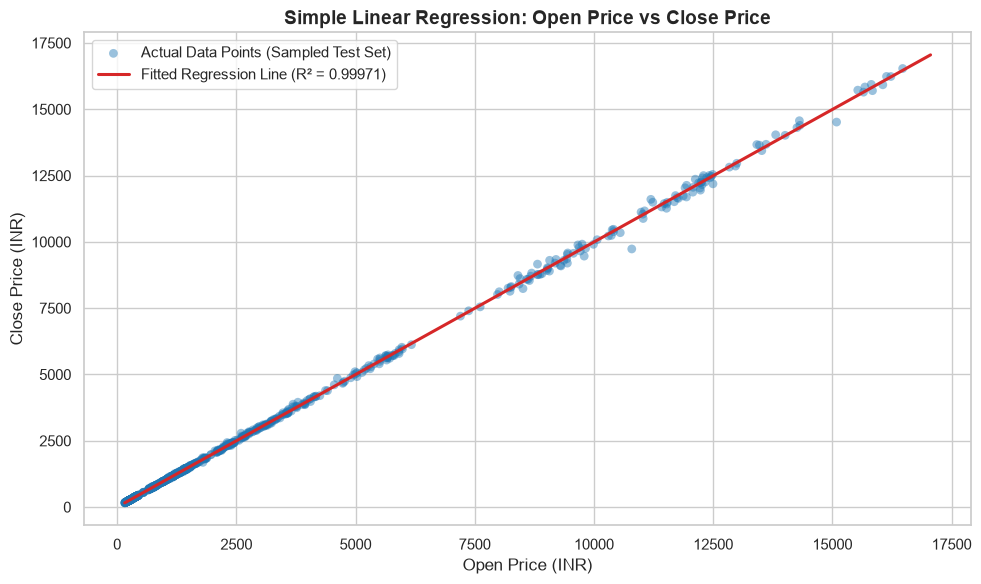

In [4]:
# Sample test points for clean visual rendering
sample_df = pd.DataFrame({
    'Open_Price': X_test_s['Open_Price'],
    'Actual_Close': y_test_s,
    'Predicted_Close': y_pred_s
}).sample(n=min(1000, len(X_test_s)), random_state=42)

plt.figure(figsize=(10, 6))
plt.scatter(
    sample_df['Open_Price'],
    sample_df['Actual_Close'],
    alpha=0.45,
    color='#1f77b4',
    edgecolors='none',
    s=40,
    label='Actual Data Points (Sampled Test Set)'
)

# Sort X for a clean continuous regression line
sorted_idx = np.argsort(X_test_s['Open_Price'].values)
plt.plot(
    X_test_s['Open_Price'].values[sorted_idx],
    y_pred_s[sorted_idx],
    color='#d62728',
    linewidth=2.2,
    label=f'Fitted Regression Line (R² = {r2_simple:.5f})'
)

plt.title('Simple Linear Regression: Open Price vs Close Price')
plt.xlabel('Open Price (INR)')
plt.ylabel('Close Price (INR)')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

---
### 6. Multiple Linear Regression (`Open_Price`, `High_Price`, `Low_Price`, `Volume` $\rightarrow$ `Close_Price`)
- **Independent Variables ($X$):** `['Open_Price', 'High_Price', 'Low_Price', 'Volume']`
- **Dependent Variable ($y$):** `Close_Price`
- **Train-Test Split:** 80% Training / 20% Testing (`test_size=0.2, random_state=42`)

In [5]:
# Define features (X) and target (y)
features_multi = ['Open_Price', 'High_Price', 'Low_Price', 'Volume']
X_multi = df[features_multi]
y_multi = df['Close_Price']

# Split dataset into 80% training and 20% testing
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multi, y_multi, test_size=0.2, random_state=42
)

# Initialize and train Multiple Linear Regression model
mlr_model = LinearRegression()
mlr_model.fit(X_train_m, y_train_m)

# Predict on the test set
y_pred_m = mlr_model.predict(X_test_m)

# Calculate evaluation metrics
r2_multi = r2_score(y_test_m, y_pred_m)
mse_multi = mean_squared_error(y_test_m, y_pred_m)

print("=== Multiple Linear Regression Results ===")
print(f"Intercept (b0):           {mlr_model.intercept_:.4f}")
print("\nFeature Coefficients:")
for feat, coef in zip(features_multi, mlr_model.coef_):
    print(f"  - {feat:<12}: {coef:.8f}")

print(f"\nR² Score:                 {r2_multi:.6f}")
print(f"Mean Squared Error (MSE): {mse_multi:.4f}")

# Display first 10 Actual vs Predicted values
mlr_comparison = pd.DataFrame({
    'Open_Price': X_test_m['Open_Price'].values[:10],
    'High_Price': X_test_m['High_Price'].values[:10],
    'Low_Price': X_test_m['Low_Price'].values[:10],
    'Volume': X_test_m['Volume'].values[:10],
    'Actual_Close_Price': y_test_m.values[:10],
    'Predicted_Close_Price': np.round(y_pred_m[:10], 2),
    'Residual_Error': np.round(y_test_m.values[:10] - y_pred_m[:10], 2)
})
print("\nFirst 10 Test Predictions (Actual vs Predicted):")
display(mlr_comparison)

=== Multiple Linear Regression Results ===
Intercept (b0):           -0.5343

Feature Coefficients:
  - Open_Price  : -0.49487178
  - High_Price  : 0.80605602
  - Low_Price   : 0.68799370
  - Volume      : 0.00000000

R² Score:                 0.999951
Mean Squared Error (MSE): 496.1953

First 10 Test Predictions (Actual vs Predicted):


,Open_Price,High_Price,Low_Price,Volume,Actual_Close_Price,Predicted_Close_Price,Residual_Error
0,317.06,320.05,317.06,4261023,319.17,318.68,0.49
1,215.39,219.84,214.48,39164340,219.06,217.66,1.40
2,402.38,403.09,398.94,4822343,400.56,399.72,0.84
3,1341.50,1345.50,1310.00,1278279,1310.00,1321.42,-11.42
4,2384.29,2384.29,2320.14,1357416,2324.07,2337.66,-13.59
5,1552.52,1560.08,1529.58,4600004,1538.38,1541.02,-2.64
6,335.22,342.96,331.50,13770080,342.36,338.10,4.26
7,229.85,235.18,228.60,21887890,234.88,232.57,2.31
8,1206.39,1251.81,1206.39,36032600,1243.88,1241.49,2.39
9,787.03,794.83,782.93,11813750,791.70,789.32,2.38


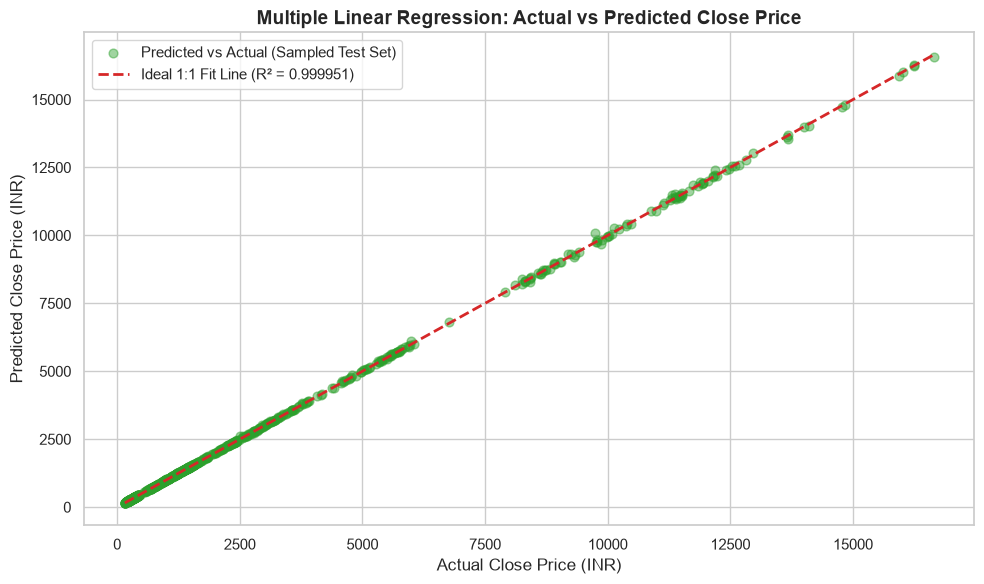

In [6]:
# Visualize Actual vs Predicted Close Price for Multiple Linear Regression
plt.figure(figsize=(10, 6))
plt.scatter(
    y_test_m[:1000],
    y_pred_m[:1000],
    alpha=0.45,
    color='#2ca02c',
    s=40,
    label='Predicted vs Actual (Sampled Test Set)'
)
min_val = min(y_test_m.min(), y_pred_m.min())
max_val = max(y_test_m.max(), y_pred_m.max())
plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    color='#d62728',
    linestyle='--',
    linewidth=2,
    label=f'Ideal 1:1 Fit Line (R² = {r2_multi:.6f})'
)
plt.title('Multiple Linear Regression: Actual vs Predicted Close Price')
plt.xlabel('Actual Close Price (INR)')
plt.ylabel('Predicted Close Price (INR)')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

---
### 7. Predict Close Price for a New Market Instance
Test the trained **Multiple Linear Regression** model on an unseen synthetic trading session (`Open_Price = 2500`, `High_Price = 2540`, `Low_Price = 2490`, `Volume = 1500000`).

In [7]:
new_market_instance = pd.DataFrame({
    'Open_Price': [2500.00],
    'High_Price': [2540.00],
    'Low_Price': [2490.00],
    'Volume': [1500000]
})

predicted_close = mlr_model.predict(new_market_instance)[0]

print("Input Market Instance:")
display(new_market_instance)
print(f"Predicted Close_Price: ₹{predicted_close:.2f}")

Input Market Instance:


,Open_Price,High_Price,Low_Price,Volume
0,2500.0,2540.0,2490.0,1500000


Predicted Close_Price: ₹2522.77


---
### 8. Side-by-Side Model Comparison
Compare the performance of **Simple Linear Regression** and **Multiple Linear Regression** using $R^2$ Score and Mean Squared Error ($\text{MSE}$).

In [8]:
comparison_df = pd.DataFrame({
    'Model': ['Simple Linear Regression', 'Multiple Linear Regression'],
    'Independent Variables': [
        'Open_Price',
        'Open_Price, High_Price, Low_Price, Volume'
    ],
    'R² Score': [round(r2_simple, 6), round(r2_multi, 6)],
    'Mean Squared Error (MSE)': [round(mse_simple, 4), round(mse_multi, 4)],
    'Root Mean Squared Error (RMSE)': [
        round(np.sqrt(mse_simple), 4),
        round(np.sqrt(mse_multi), 4)
    ]
})

mse_reduction_pct = ((mse_simple - mse_multi) / mse_simple) * 100
print(f"MSE Reduction from Simple to Multiple Linear Regression: {mse_reduction_pct:.2f}%\n")
display(comparison_df)

MSE Reduction from Simple to Multiple Linear Regression: 83.24%



,Model,Independent Variables,R² Score,Mean Squared Error (MSE),Root Mean Squared Error (RMSE)
0,Simple Linear Regression,Open_Price,0.999706,2960.9407,54.4145
1,Multiple Linear Regression,"Open_Price, High_Price, Low_Price, Volume",0.999951,496.1953,22.2754


---
### 9. Conclusion

#### Key Analytical Findings:
1. **Simple Linear Regression Performance:** Using `Open_Price` alone yields a high $R^2$ score ($0.999706$) because daily stock prices span a wide scale across tickers (₹150 to ₹16,000+), where the opening price anchors the price level. However, it cannot account for intraday price swings between market open and close, resulting in a Mean Squared Error of $\text{MSE} = 2960.9407$ ($\text{RMSE} = ₹54.41$).
2. **Multiple Linear Regression Improvement:** Incorporating intraday range bounds (`High_Price` and `Low_Price`) and `Volume` boosts $R^2$ to $0.999951$ and reduces the Mean Squared Error by **$83.24\%$** ($\text{MSE} = 496.1953$, $\text{RMSE} = ₹22.28$).
3. **Econometric Interpretation of Coefficients:**
   - `High_Price` ($\beta_2 = +0.8061$) and `Low_Price` ($\beta_3 = +0.6880$) carry strong positive weights, while `Open_Price` ($\beta_1 = -0.4949$) acts as a counterweight: this aligns with financial microstructure theory where the closing price settles near the intraday high/low midpoint adjusted for the opening anchor ($\text{Close} \approx 0.81\,\text{High} + 0.69\,\text{Low} - 0.49\,\text{Open}$).
4. **Readiness for Experiment 05:** With continuous price prediction established via linear regression, the dataset and engineered features are ready for **Experiment 05**.

---
### 10. Auto-export Utility
Convert `DWM_Lab_4_Stock_Market.ipynb` to `DWM_Lab_4_Stock_Market.html` using `nbconvert`.

In [9]:
import subprocess
import sys
from pathlib import Path

notebook_path = Path("DWM_Lab_4_Stock_Market.ipynb")
if notebook_path.exists():
    cmd = [
        sys.executable, "-m", "jupyter", "nbconvert",
        "--to", "html", "--no-prompt", str(notebook_path)
    ]
    result = subprocess.run(cmd, capture_output=True, text=True)
    if result.returncode == 0:
        print("Successfully exported DWM_Lab_4_Stock_Market.html")
    else:
        print("Export notice:", result.stderr)
else:
    print("Notebook file will be exported upon save.")

Successfully exported DWM_Lab_4_Stock_Market.html
